In [1]:
import time
from dataclasses import dataclass
from datetime import datetime
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import FashionMNIST

from mlkit.blocks.activations import Activation, LeakyReLU, ReLU, SiLU
from mlkit.blocks.embeddings import TimeEmbeddingConfig
from mlkit.blocks.unet import UNetBlockConfig
from mlkit.core.callbacks import MLflowLogger, ModelCheckpoint, ProgressLogger
from mlkit.core.history import History
from mlkit.core.trainer import Trainer
from mlkit.data.splitter import StratifiedSplitter
from mlkit.metrics.collections import image_metrics
from mlkit.models.unet import UNet, UNetConfig
from mlkit.tasks.diffusion import CosineSchedule, DiffusionTask, LinearSchedule, NoiseSchedule
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.utils.tracking import flatten_params, setup_mlflow
from mlkit.visual.curves import plot_comparison
from mlkit.visual.images import plot_image_grid
from mlkit.visual.samples import SampleGrid
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

import mlflow

setup_logging()
use_style()

ROOT = Path("../..")
DATA_DIR = ROOT / "datasets/raw"
setup_mlflow(ROOT, "lab2.4")

SEED = 42
IMAGE_SHAPE = (1, 28, 28)
VAL_FRACTION = 0.1

STEPS = 200
SCHEDULE = CosineSchedule()
VARIANCE = "posterior"

CHANNELS = (64, 128, 256)
DROPOUT = 0.1
EMBEDDING_DIM = 64
TIME_DIM = 256

BATCH_SIZE = 128
EPOCHS = 30
LEARNING_RATE = 5e-4

SAMPLE_EVERY = 5
NUM_SAMPLES = 32
NUM_GENERATED = 64
STAGE_IMAGES = 4
STAGE_STEPS = (150, 100, 50, 25, 0)

RESTORE_STEPS = (25, 50, 100, 150)
RESTORE_SHOWN = 8
RESTORE_EVAL = 500
RESTORE_REPEATS = 3

RUN_NAME = f"lab2.4_{datetime.now():%Y%m%d_%H%M%S}"
saver = FigureSaver(Path("artifacts") / RUN_NAME)

In [2]:
train_raw = FashionMNIST(DATA_DIR, train=True, download=True)
test_raw = FashionMNIST(DATA_DIR, train=False, download=True)
class_counts = pd.Series(train_raw.targets.numpy()).value_counts().sort_index()

print(f"Train: {len(train_raw)} | test: {len(test_raw)} | image: {tuple(train_raw.data.shape[1:])} | dtype: {train_raw.data.dtype}")
print(f"Classes: {len(train_raw.classes)} | per class: from {class_counts.min()} to {class_counts.max()}")
print(", ".join(train_raw.classes))

100.0%
100.0%
100.0%
100.0%

Train: 60000 | test: 10000 | image: (28, 28) | dtype: torch.uint8
Classes: 10 | per class: from 6000 to 6000
T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot


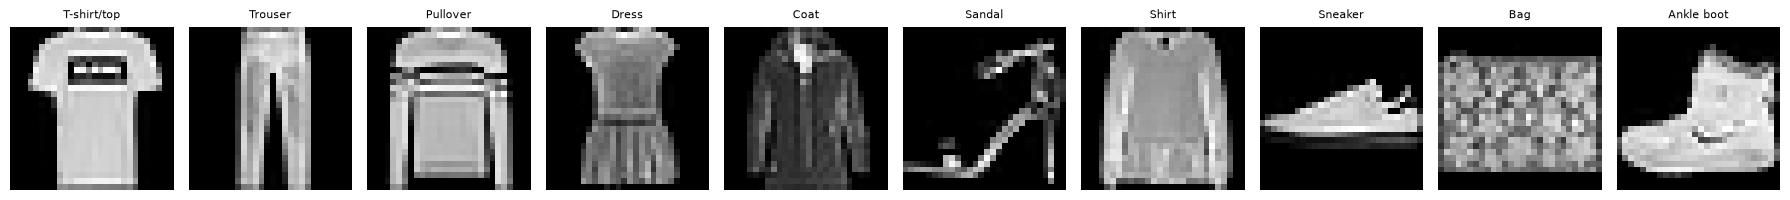

In [3]:
first_of_class = [int(torch.nonzero(train_raw.targets == label)[0]) for label in range(len(train_raw.classes))]
examples = train_raw.data[first_of_class].unsqueeze(1).float() / 255
saver.save(plot_image_grid(examples, train_raw.classes, ncols=10), "samples");

In [4]:
def to_model_range(data: torch.Tensor) -> torch.Tensor:
    return data.unsqueeze(1).float() / 127.5 - 1


train_indices, val_indices = StratifiedSplitter((1 - VAL_FRACTION, VAL_FRACTION), seed=SEED).split(train_raw.targets.tolist())
images = to_model_range(train_raw.data)
train_images, val_images = images[train_indices], images[val_indices]
test_images = to_model_range(test_raw.data)

train_loader = DataLoader(train_images, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, pin_memory=True)
val_loader = DataLoader(val_images, batch_size=2 * BATCH_SIZE, pin_memory=True)
test_loader = DataLoader(test_images, batch_size=2 * BATCH_SIZE, pin_memory=True)

print(f"Train: {tuple(train_images.shape)} | val: {tuple(val_images.shape)} | test: {tuple(test_images.shape)}")
print(f"Range: [{images.min().item():.1f}, {images.max().item():.1f}]")

Train: (54000, 1, 28, 28) | val: (6000, 1, 28, 28) | test: (10000, 1, 28, 28)
Range: [-1.0, 1.0]


,linear,cosine
t = 25,0.9680,0.9578
t = 50,0.8801,0.8470
t = 100,0.6025,0.4938
t = 150,0.3204,0.1443
t = 200,0.1322,0.0000


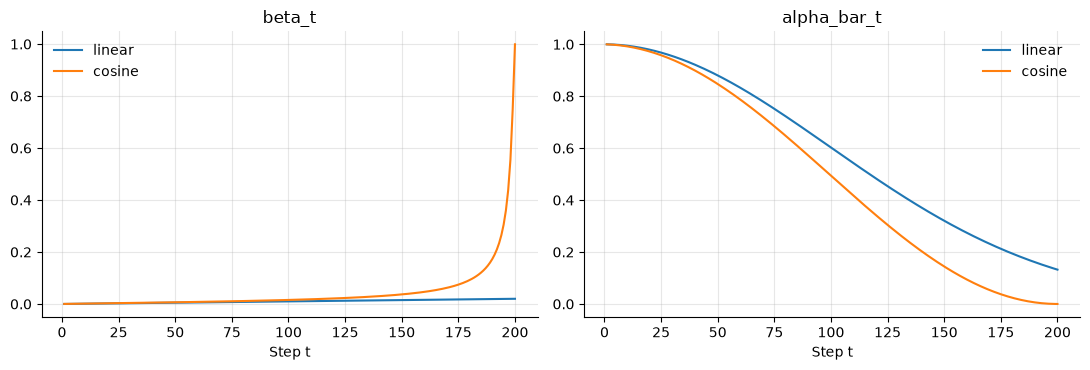

In [5]:
schedules = {
    "linear": NoiseSchedule(STEPS, LinearSchedule(1e-4, 0.02)),
    "cosine": NoiseSchedule(STEPS, CosineSchedule()),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
steps_axis = np.arange(1, STEPS + 1)
for name, schedule in schedules.items():
    axes[0].plot(steps_axis, schedule.betas.numpy(), label=name)
    axes[1].plot(steps_axis, schedule.alpha_bars.numpy(), label=name)
for ax, title in zip(axes, ["beta_t", "alpha_bar_t"]):
    ax.set_xlabel("Step t")
    ax.set_title(title)
    ax.legend()
fig.tight_layout()
saver.save(fig, "schedules")

pd.DataFrame({
    name: {f"t = {step}": schedule.alpha_bars[step - 1].item() for step in (*RESTORE_STEPS, STEPS)}
    for name, schedule in schedules.items()
}).round(4)

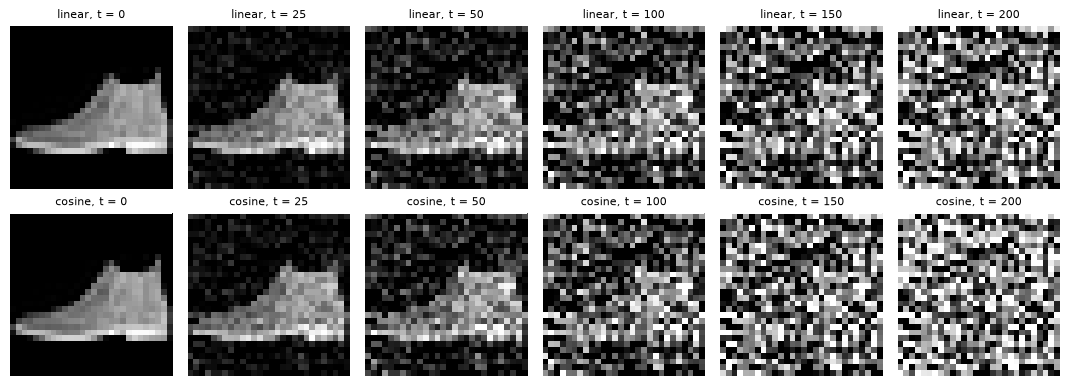

In [6]:
shown_steps = (0, *RESTORE_STEPS, STEPS)
image = test_images[:1]
noise = torch.randn(image.shape, generator=torch.Generator().manual_seed(SEED))

rows: list[torch.Tensor] = []
titles: list[str] = []
for name, schedule in schedules.items():
    for step in shown_steps:
        noisy = image if step == 0 else schedule.add_noise(image, torch.tensor([step - 1]), noise)
        rows.append(((noisy + 1) / 2).clamp(0, 1))
        titles.append(f"{name}, t = {step}")

saver.save(plot_image_grid(torch.cat(rows), titles, ncols=len(shown_steps)), "forward_process");

In [7]:
def unet_config(activation: Activation) -> UNetConfig:
    return UNetConfig(
        in_channels=IMAGE_SHAPE[0],
        input_size=IMAGE_SHAPE[1:],
        blocks=tuple(UNetBlockConfig(channels, activation=activation, dropout=DROPOUT) for channels in CHANNELS),
        time=TimeEmbeddingConfig(EMBEDDING_DIM, TIME_DIM, activation=activation),
    )


model = UNet(unet_config(SiLU()))
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print("Output:", tuple(model(torch.zeros(2, *IMAGE_SHAPE), torch.zeros(2, dtype=torch.long)).shape))

Unet(
  (time): TimeEmbedding(
    (0): SinusoidalTimeEmbedding()
    (1): Linear(in_features=64, out_features=256, bias=True)
    (2): SiLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
  (stem): ConvBlock(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (encoder): ModuleList(
    (0): UNetBlock(
      (conv1): ConvBlock(
        (0): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (1): SiLU()
        (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (time): Sequential(
        (0): SiLU()
        (1): Linear(in_features=256, out_features=64, bias=True)
      )
      (conv2): ConvBlock(
        (0): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (1): SiLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (skip): Identity()
    )
    (1): UNetBlock(
      (conv1): ConvBlock(
        (0):

In [8]:
VARIANTS: dict[str, Activation] = {
    "relu": ReLU(),
    "leaky_relu": LeakyReLU(),
    "silu": SiLU(),
}


@dataclass
class RunResult:
    task: DiffusionTask
    history: History
    test: dict[str, float]
    seconds: float
    run_id: str


def run(name: str, activation: Activation) -> RunResult:
    seed_everything(SEED)
    config = unet_config(activation)
    task = DiffusionTask(
        model=UNet(config),
        optimizer=partial(torch.optim.Adam, lr=LEARNING_RATE),
        schedule=NoiseSchedule(STEPS, SCHEDULE),
        image_shape=IMAGE_SHAPE,
        variance=VARIANCE,
        metrics=image_metrics(),
    )
    sample_z = torch.randn(NUM_SAMPLES, *IMAGE_SHAPE, generator=torch.Generator().manual_seed(SEED))

    with mlflow.start_run(run_name=name) as active_run:
        mlflow.log_params(
            flatten_params(config)
            | {f"schedule.{key}": value for key, value in flatten_params(SCHEDULE).items()}
            | {
                "activation": name,
                "schedule": type(SCHEDULE).__name__,
                "steps": STEPS,
                "variance": VARIANCE,
                "optimizer": "Adam",
                "learning_rate": LEARNING_RATE,
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
            }
        )
        trainer = Trainer(callbacks=[
            ProgressLogger(),
            MLflowLogger(),
            ModelCheckpoint(task, monitor="val/loss", mode="min"),
            SampleGrid(
                lambda: task.generate(z=sample_z, generator=torch.Generator().manual_seed(SEED)),
                FigureSaver(saver.directory / name),
                every=SAMPLE_EVERY,
            ),
        ])
        start = time.perf_counter()
        history = trainer.fit(task, train_loader, val_loader, epochs=EPOCHS)
        seconds = time.perf_counter() - start

        seed_everything(SEED)
        test = trainer.evaluate(task, test_loader)
        mlflow.log_metrics({f"test/{key}": value for key, value in test.items()})

    return RunResult(task, history, test, seconds, active_run.info.run_id)

In [9]:
results: dict[str, RunResult] = {}
for name, activation in VARIANTS.items():
    print(f"===== {name}")
    results[name] = run(name, activation)

===== relu
Epoch 1 | train/loss 0.1425 val/loss 0.09186 val/mse 0.03269 val/psnr 19.22 val/ssim 0.562 | 50.7s
Epoch 2 | train/loss 0.09176 val/loss 0.08246 val/mse 0.03272 val/psnr 19.7 val/ssim 0.5714 | 47.1s
Epoch 3 | train/loss 0.08457 val/loss 0.07883 val/mse 0.03233 val/psnr 19.83 val/ssim 0.6216 | 46.7s
Epoch 4 | train/loss 0.08029 val/loss 0.07707 val/mse 0.02489 val/psnr 20.39 val/ssim 0.6669 | 45.3s
Epoch 5 | train/loss 0.07753 val/loss 0.07429 val/mse 0.02488 val/psnr 20.52 val/ssim 0.7084 | 45.8s
Epoch 6 | train/loss 0.07723 val/loss 0.07391 val/mse 0.03092 val/psnr 20.27 val/ssim 0.5839 | 48.7s
Epoch 7 | train/loss 0.07443 val/loss 0.07254 val/mse 0.02441 val/psnr 20.62 val/ssim 0.6944 | 46.4s
Epoch 8 | train/loss 0.0741 val/loss 0.07365 val/mse 0.02324 val/psnr 20.72 val/ssim 0.6935 | 46.0s
Epoch 9 | train/loss 0.07313 val/loss 0.07362 val/mse 0.02802 val/psnr 20.8 val/ssim 0.6511 | 46.2s
Epoch 10 | train/loss 0.07249 val/loss 0.07152 val/mse 0.02449 val/psnr 20.68 val/ssi

KeyboardInterrupt: 

In [ ]:
histories = {name: result.history for name, result in results.items()}
saver.save(plot_comparison(histories, ["loss"], splits=("train", "val")), "loss")
saver.save(plot_comparison(histories, ["mse", "psnr", "ssim"]), "x0_estimate_metrics");

In [ ]:
def last_epochs_std(history: History, key: str, epochs: int = 5) -> float:
    return float(np.std(history.series(key)[1][-epochs:]))


summary = pd.DataFrame({
    name: {
        "train loss (last epoch)": result.history.last("train/loss"),
        "val loss (best)": result.history.best("val/loss", "min")[1],
        "best epoch": result.history.best("val/loss", "min")[0],
        "train loss std (last 5 epochs)": last_epochs_std(result.history, "train/loss"),
        "val loss std (last 5 epochs)": last_epochs_std(result.history, "val/loss"),
        "test loss": result.test["loss"],
        "test psnr (x0 estimate)": result.test["psnr"],
        "test ssim (x0 estimate)": result.test["ssim"],
        "training time, s": result.seconds,
        "parameters": sum(p.numel() for p in result.task.model.parameters()),
    }
    for name, result in results.items()
}).T
summary.to_csv(saver.directory / "summary.csv")
summary.round(5)

In [ ]:
epochs_to_show = [0, SAMPLE_EVERY, EPOCHS // 2, EPOCHS]
fig, axes = plt.subplots(len(results), len(epochs_to_show), figsize=(4 * len(epochs_to_show), 2.6 * len(results)), squeeze=False)
for row, name in zip(axes, results):
    for ax, epoch in zip(row, epochs_to_show):
        ax.imshow(plt.imread(saver.directory / name / f"samples_epoch_{epoch:03d}.png"))
        ax.set_title(f"{name}, epoch {epoch}")
        ax.axis("off")
fig.tight_layout()
saver.save(fig, "progress");

In [ ]:
generation_noise = torch.randn(NUM_GENERATED, *IMAGE_SHAPE, generator=torch.Generator().manual_seed(SEED + 1))
generation_seconds: dict[str, float] = {}

for name, result in results.items():
    start = time.perf_counter()
    generated = result.task.generate(z=generation_noise, generator=torch.Generator().manual_seed(SEED + 1))
    generation_seconds[name] = time.perf_counter() - start
    fig = plot_image_grid(generated, ncols=8)
    fig.suptitle(name)
    saver.save(fig, f"generated_{name}")

pd.Series(generation_seconds, name=f"time to generate {NUM_GENERATED} images, s").round(2)

In [ ]:
stage_noise = generation_noise[:STAGE_IMAGES]
stage_titles = [f"t = {step}" for step in (STEPS, *STAGE_STEPS)]

for name, result in results.items():
    stages = [((stage_noise + 1) / 2).clamp(0, 1)] + [
        result.task.generate(z=stage_noise, generator=torch.Generator().manual_seed(SEED + 1), remaining=remaining)
        for remaining in STAGE_STEPS
    ]
    grid = torch.stack(stages, dim=1).flatten(0, 1)
    titles = stage_titles + [""] * (len(grid) - len(stage_titles))
    fig = plot_image_grid(grid, titles, ncols=len(stages))
    fig.suptitle(f"{name}: reverse process")
    saver.save(fig, f"stages_{name}")

In [ ]:
shown = test_images[:RESTORE_SHOWN]

for steps in RESTORE_STEPS:
    restore_rows = {"original": (shown + 1) / 2}
    for name, result in results.items():
        noisy, restored = result.task.restore(shown, steps, generator=torch.Generator().manual_seed(SEED))
        restore_rows.setdefault("noisy", noisy)
        restore_rows[name] = restored

    titles = [label if column == 0 else "" for label in restore_rows for column in range(RESTORE_SHOWN)]
    fig = plot_image_grid(torch.cat(list(restore_rows.values())), titles, ncols=RESTORE_SHOWN)
    fig.suptitle(f"Restoration from t0 = {steps}")
    saver.save(fig, f"restore_t{steps:03d}")

In [ ]:
def image_scores(preds: torch.Tensor, target: torch.Tensor) -> dict[str, float]:
    metrics = image_metrics()
    metrics.update(preds, target)
    return {name: float(value) for name, value in metrics.compute().items()}


eval_images = test_images[:RESTORE_EVAL]
eval_target = (eval_images + 1) / 2

records: list[dict[str, float | int | str]] = []
for steps in RESTORE_STEPS:
    for repeat in range(RESTORE_REPEATS):
        for name, result in results.items():
            noisy, restored = result.task.restore(eval_images, steps, generator=torch.Generator().manual_seed(SEED + repeat))
            records.append({"model": name, "t0": steps, "repeat": repeat} | image_scores(restored, eval_target))
        records.append({"model": "noisy input", "t0": steps, "repeat": repeat} | image_scores(noisy, eval_target))

restoration = pd.DataFrame(records)
restoration_table = restoration.groupby(["model", "t0"])[["mse", "psnr", "ssim"]].agg(["mean", "std"])
restoration_table.to_csv(saver.directory / "restoration.csv")
restoration_table.round(4)

In [ ]:
restoration_means = restoration.groupby(["model", "t0"])[["mse", "psnr", "ssim"]].mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metric in zip(axes, ["mse", "psnr", "ssim"]):
    for model_name in restoration_means.index.get_level_values("model").unique():
        series = restoration_means.loc[model_name, metric]
        ax.plot(series.index, series.values, marker="o", label=model_name)
    ax.set_xticks(RESTORE_STEPS)
    ax.set_xlabel("t0")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.legend()
fig.tight_layout()
saver.save(fig, "restoration_metrics")

for name, result in results.items():
    with mlflow.start_run(run_id=result.run_id):
        mlflow.log_metrics({
            f"restore/{metric}_t{steps:03d}": float(restoration_means.loc[(name, steps), metric])
            for steps in RESTORE_STEPS
            for metric in ("mse", "psnr", "ssim")
        })